## SHAP ANALYSIS

In [11]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA_DIR = next(p for p in (Path("data/processed"), Path("../data/processed"))
                if (p / "paysim_features.parquet").exists())
MODEL_DIR = DATA_DIR.parent.parent / "models"
MODEL_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TARGET, SPLIT_KEY = "isFraud", "step"
N_TRIALS = 30          # 30 is enough to learn the workflow; raise to 60-100 for a final run
EXPERIMENT_NAME = "paysim-fraud-xgboost"

In [12]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [13]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

DATA_DIR = next(
    p for p in (Path("data/processed"), Path("../data/processed"))
    if (p / "paysim_features.parquet").exists()
)
MODEL_DIR = DATA_DIR.parent.parent / "models"

print("SHAP version:", shap.__version__)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

SHAP version: 0.54.1
Data directory: ../data/processed
Model directory: ../models


## LOAD THE DATA

In [14]:
meta = json.loads((MODEL_DIR / "model_meta_tuned.json").read_text())
df = pd.read_parquet(DATA_DIR / "paysim_features.parquet")
df = df.sort_values("step", kind="stable").reset_index(drop=True)

FEATURES = meta["features"]
TARGET = "isFraud"
train_end = meta["split"]["train_end_step"]
valid_end = meta["split"]["valid_end_step"]

valid = df[(df["step"] > train_end) & (df["step"] <= valid_end)].copy()
X_valid = valid[FEATURES]
y_valid = valid[TARGET]

model = xgb.XGBClassifier()
model.load_model(str(MODEL_DIR / "xgb_fraud_tuned.json"))

print(f"Validation rows: {len(valid):,}")
print(f"Features: {len(FEATURES)}")
print(f"Validation fraud cases: {int(y_valid.sum()):,}")
print("Saved validation PR-AUC:", meta.get("validation_metrics", {}).get("pr_auc"))

Validation rows: 410,437
Features: 8
Validation fraud cases: 560
Saved validation PR-AUC: 0.9435948506643126


## create shap explainations

In [15]:
SAMPLE_SIZE = min(1000, len(X_valid))
X_explain = X_valid.sample(n=SAMPLE_SIZE, random_state=42)

explainer = shap.TreeExplainer(model)
shap_exp = explainer(X_explain)

print("SHAP values shape:", shap_exp.values.shape)
print("Explained rows:", len(X_explain))

SHAP values shape: (1000, 8)
Explained rows: 1000


### global explaination

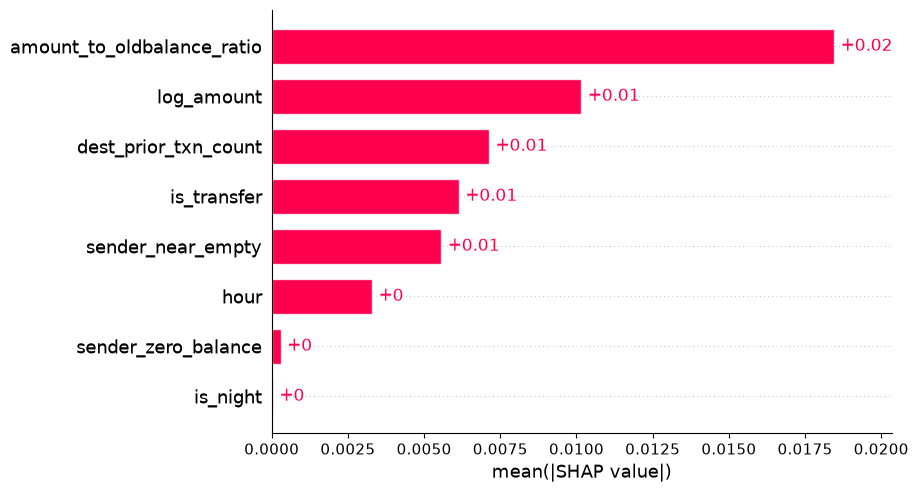

In [16]:
shap.plots.bar(
    shap_exp,max_display=15
)

### Direction and spread of features effects

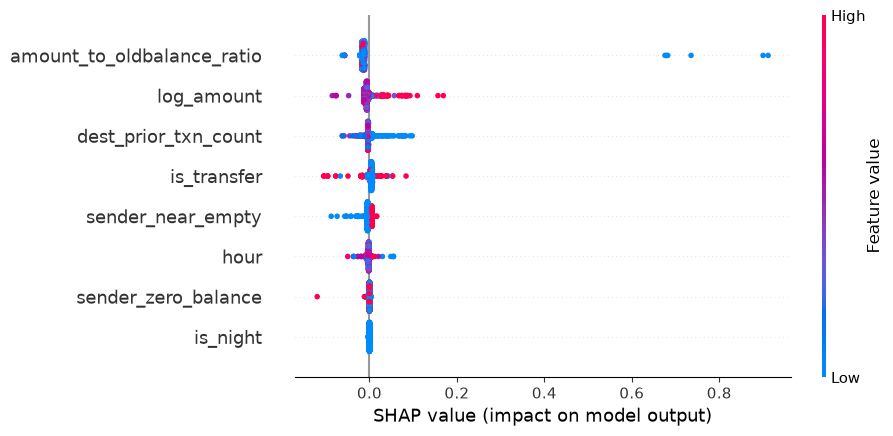

In [17]:
shap.plots.beeswarm(shap_exp,max_display=15
   
)

#### Local iexplaination 
why did this transaction received this score

ROW index in explained sample:  0
predicted fraud probability:  0.100097


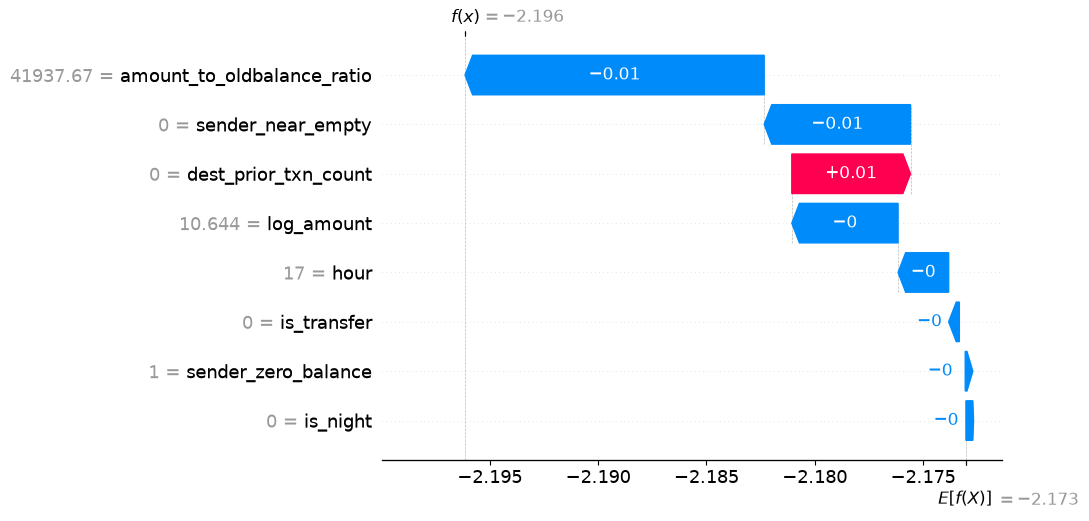

In [18]:
ROW_INDEX = 0
row = X_explain.iloc[[ROW_INDEX]]
predicted_probability = model.predict_proba(row)[0,1]
print("ROW index in explained sample: ", ROW_INDEX)
print("predicted fraud probability: ", round(float(predicted_probability),6))
shap.plots.waterfall(shap_exp[ROW_INDEX], max_display=15)